# Workstream A, step 1: a model that sees the community

**Question.** Real gain falls when newcomers compete with their own community (δ < 0), even when the model is retrained every round. Is that because the model cannot see how large the community in a state already is?

**Set-up.** Three versions of the same gradient-boosting model, all trained only on observed outcomes:

| features | what the model sees besides the person and the state |
|---|---|
| `base` | nothing (the v2 model) |
| `community` | share of co-nationals among all foreigners in the state, C[state, origin] |
| `community_recent` | the same plus the share of last round's arrivals, R[state, origin] |

Grid: `configs/community_model.yaml` (54 points × 5 seeds). This notebook only reads `results/community_model/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from refugee_sim.simulation import load_results

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

runs = load_results("../results/community_model")
print(f"{runs['run_key'].nunique()} runs loaded")

FEATURES = ["base", "community", "community_recent"]
FEATURE_LABEL = {"base": "does not see community", "community": "sees community",
                 "community_recent": "sees community + recent arrivals"}
FEATURE_COLOR = {"base": "#555555", "community": "#2F6FB5", "community_recent": "#E07B28"}
POLICY_STYLE = {"fixed": "--", "every_round": "-"}
SCENARIOS = ["SOEP", "none", "stylised x4"]
DELTAS = [-0.3, 0.0, 0.3]


def mean_by_round(df, column):
    return df.groupby("round")[column].mean()

270 runs loaded


## 1. Real gain over random quota placement

Rows: interaction scenario (SOEP is the main one). Columns: community effect δ. Solid = retrained every round, dashed = fixed model. Dotted = best possible gain (oracle).

Note: for the fixed model the two community versions coincide, because it is trained once on the historical data, where no recent arrivals exist yet (R = 0).

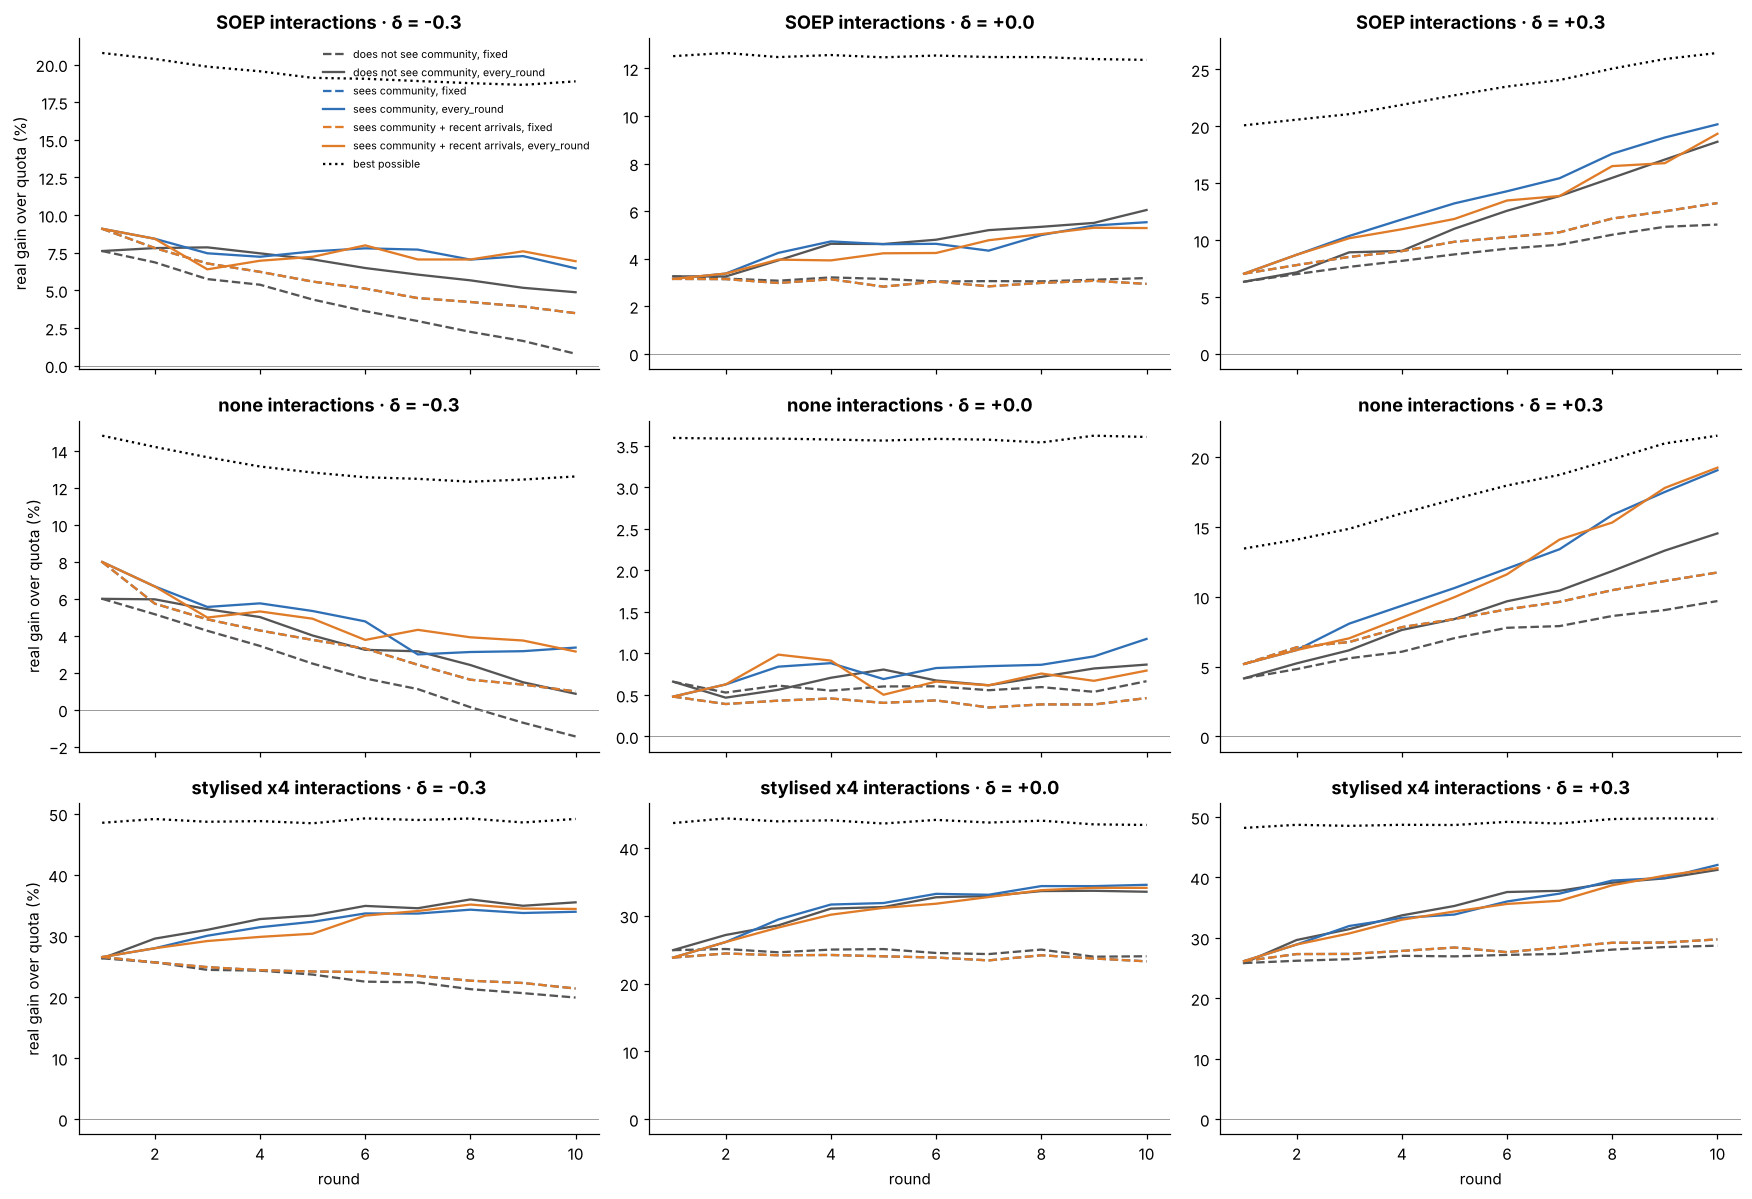

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
for i, s in enumerate(SCENARIOS):
    for j, d in enumerate(DELTAS):
        ax = axes[i, j]
        cell = runs[(runs["interactions"] == s) & (runs["delta"] == d)]
        for f in FEATURES:
            for p, ls in POLICY_STYLE.items():
                g = mean_by_round(cell[(cell["features"] == f) & (cell["policy"] == p)], "gain_pct")
                ax.plot(g.index, g, ls, color=FEATURE_COLOR[f], label=f"{FEATURE_LABEL[f]}, {p}")
        oracle = mean_by_round(cell[(cell["features"] == "base") & (cell["policy"] == "fixed")], "oracle_gain_pct")
        ax.plot(oracle.index, oracle, ":", color="k", label="best possible")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(f"{s} interactions · δ = {d:+.1f}", fontweight="bold")
        if j == 0:
            ax.set_ylabel("real gain over quota (%)")
        if i == 2:
            ax.set_xlabel("round")
axes[0, 0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_real_gain.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Round 1 vs round 10

`captured_pct` = share of the best possible gain the model achieves; `promised_gain_pct` = gain the model itself expects.

In [3]:
COLUMNS = ["gain_pct", "captured_pct", "promised_gain_pct"]
table = (runs[runs["round"].isin([1, 10])]
         .groupby(["interactions", "delta", "policy", "features", "round"])[COLUMNS].mean()
         .unstack("round").round(1))
table.loc[["SOEP"]]

gain_pct       captured_pct  \
round                                                 1     10           1    
interactions delta policy      features                                       
SOEP         -0.3  every_round base                  7.6   4.9         36.7   
                               community             9.1   6.5         43.8   
                               community_recent      9.1   6.9         43.8   
                   fixed       base                  7.6   0.8         36.7   
                               community             9.1   3.5         43.8   
                               community_recent      9.1   3.5         43.8   
              0.0  every_round base                  3.3   6.0         26.0   
                               community             3.1   5.5         25.2   
                               community_recent      3.1   5.3         25.2   
                   fixed       base                  3.3   3.2         26.0   
                               community             3.1   2.9         25.2   
                               community_recent      3.1   2.9         25.2   
              0.3  every_round base                  6.3  18.6         31.5   
                               community             7.0  20.2         35.0   
                               community_recent      7.0  19.3         35.0   
                   fixed       base                  6.3  11.4         31.5   
                               community             7.0  13.3         35.0   
                               community_recent      7.0  13.3         35.0   

                                                      promised_gain_pct        
round                                              10                1     10  
interactions delta policy      features                                        
SOEP         -0.3  every_round base              27.1              32.9  24.5  
                               community         39.8              37.1  14.9  
                               community_recent  41.8              37.1  15.3  
                   fixed       base               4.3              32.9  47.6  
                               community         20.3              37.1  32.0  
                               community_recent  20.3              37.1  32.0  
              0.0  every_round base              48.9              30.7  13.8  
                               community         44.7              31.2  12.3  
                               community_recent  42.8              31.2  13.1  
                   fixed       base              25.9              30.7  29.6  
                               community         23.8              31.2  27.6  
                               community_recent  23.8              31.2  27.6  
              0.3  every_round base              66.9              33.7   9.6  
                               community         67.1              35.3  18.2  
                               community_recent  67.0              35.3  16.1  
                   fixed       base              42.5              33.7  13.2  
                               community         48.8              35.3  17.3  
                               community_recent  48.8              35.3  17.3

In [4]:
table.loc[["none", "stylised x4"]]

gain_pct       captured_pct  \
round                                                 1     10           1    
interactions delta policy      features                                       
none         -0.3  every_round base                  6.0   0.9         40.5   
                               community             8.0   3.4         53.9   
                               community_recent      8.0   3.1         53.9   
                   fixed       base                  6.0  -1.4         40.5   
                               community             8.0   1.0         53.9   
                               community_recent      8.0   1.0         53.9   
              0.0  every_round base                  0.7   0.9         18.6   
                               community             0.5   1.2         13.5   
                               community_recent      0.5   0.8         13.5   
                   fixed       base                  0.7   0.7         18.6   
                               community             0.5   0.5         13.5   
                               community_recent      0.5   0.5         13.5   
              0.3  every_round base                  4.2  14.5         30.9   
                               community             5.2  19.1         38.5   
                               community_recent      5.2  19.2         38.5   
                   fixed       base                  4.2   9.7         30.9   
                               community             5.2  11.7         38.5   
                               community_recent      5.2  11.7         38.5   
stylised x4  -0.3  every_round base                 26.3  35.5         54.2   
                               community            26.5  33.9         54.7   
                               community_recent     26.5  34.4         54.7   
                   fixed       base                 26.3  19.9         54.2   
                               community            26.5  21.4         54.7   
                               community_recent     26.5  21.4         54.7   
              0.0  every_round base                 24.9  33.5         57.1   
                               community            23.8  34.6         54.6   
                               community_recent     23.8  34.1         54.6   
                   fixed       base                 24.9  24.0         57.1   
                               community            23.8  23.3         54.6   
                               community_recent     23.8  23.3         54.6   
              0.3  every_round base                 25.8  41.3         53.6   
                               community            26.2  42.1         54.3   
                               community_recent     26.2  41.5         54.3   
                   fixed       base                 25.8  28.7         53.6   
                               community            26.2  29.8         54.3   
                               community_recent     26.2  29.8         54.3   

                                                      promised_gain_pct        
round                                              10                1     10  
interactions delta policy      features                                        
none         -0.3  every_round base               8.4              31.4  22.5  
                               community         38.5              35.5  14.1  
                               community_recent  34.0              35.5  13.2  
                   fixed       base             -10.6              31.4  46.2  
                               community         10.2              35.5  30.1  
                               community_recent  10.2              35.5  30.1  
              0.0  every_round base              24.1              28.3   9.6  
                               community         32.7              30.0   9.7  
                               community_recent  22.1              30.0   9.7  
      

## 3. Does the model avoid crowded states?

Mean standardised community size z in the states where people were placed. Under competition (δ < 0) a model that understands the community should move people away from large communities, so its line should lie below the blind model's.

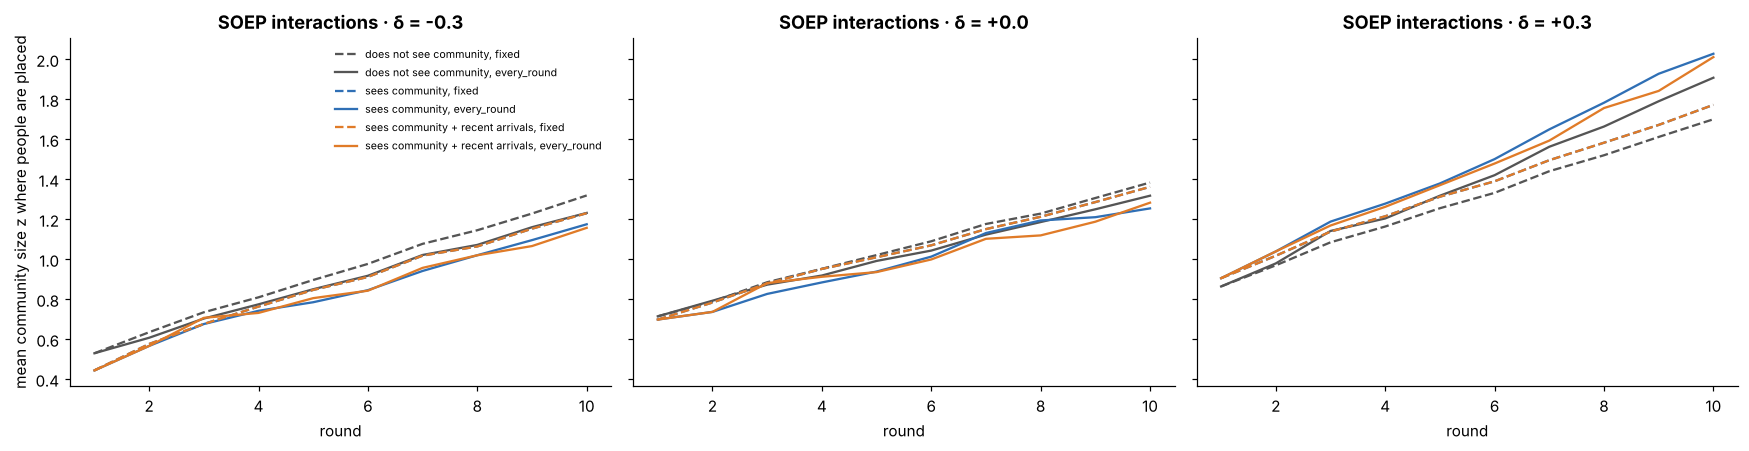

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
soep = runs[runs["interactions"] == "SOEP"]
for ax, d in zip(axes, DELTAS):
    for f in FEATURES:
        for p, ls in POLICY_STYLE.items():
            z = mean_by_round(soep[(soep["delta"] == d) & (soep["features"] == f) & (soep["policy"] == p)], "mean_z_placed")
            ax.plot(z.index, z, ls, color=FEATURE_COLOR[f], label=f"{FEATURE_LABEL[f]}, {p}")
    ax.set_title(f"SOEP interactions · δ = {d:+.1f}", fontweight="bold")
    ax.set_xlabel("round")
axes[0].set_ylabel("mean community size z where people are placed")
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_community_placed.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Promised vs real gain (SOEP, δ = −0.3)

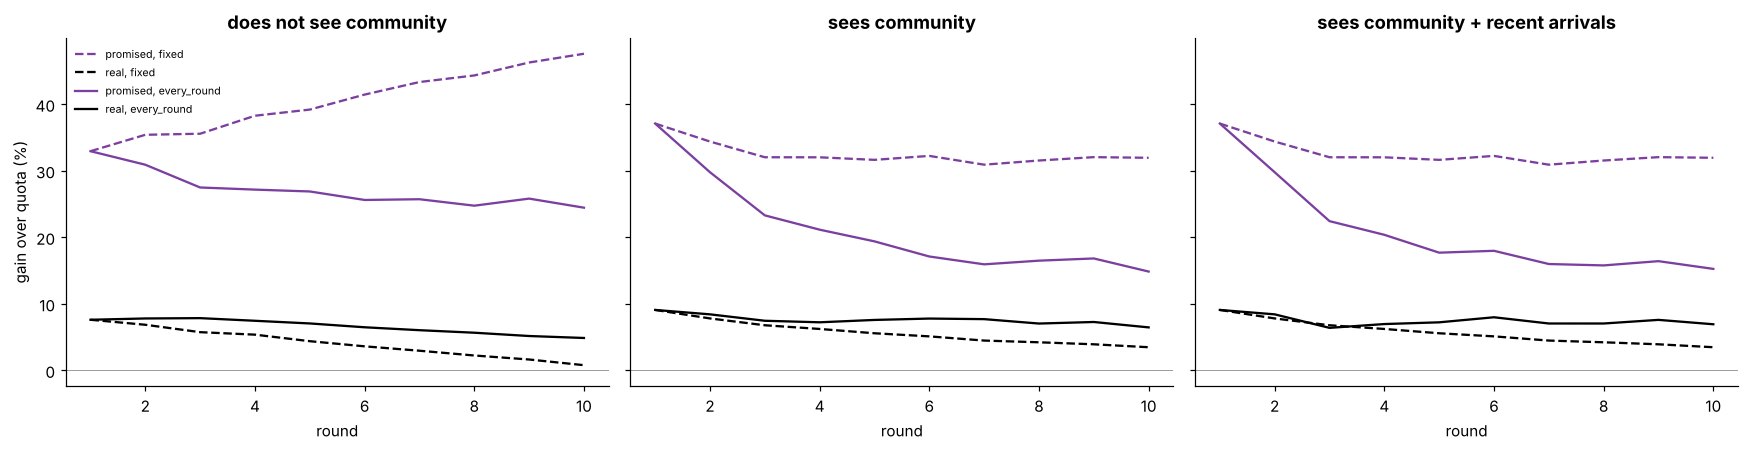

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
cell = soep[soep["delta"] == -0.3]
for ax, f in zip(axes, FEATURES):
    for p, ls in POLICY_STYLE.items():
        m = cell[(cell["features"] == f) & (cell["policy"] == p)].groupby("round")[["gain_pct", "promised_gain_pct"]].mean()
        ax.plot(m.index, m["promised_gain_pct"], ls, color="#7B3FA0", label=f"promised, {p}")
        ax.plot(m.index, m["gain_pct"], ls, color="k", label=f"real, {p}")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"{FEATURE_LABEL[f]}", fontweight="bold")
    ax.set_xlabel("round")
axes[0].set_ylabel("gain over quota (%)")
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_promised_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

## What we learn (SOEP interactions, δ = −0.3, round 10, mean of 5 seeds)

- **Seeing the community helps, but does not stop the decline.** Fixed model: real gain +0.8% → +3.5%; retrained every round: +4.9% → +6.5%. Both still fall from +9.1% in round 1.
- **The model captures more of the best possible gain:** 27% → 40–42% when retrained, 4% → 20% when fixed.
- **It promises much less, but still too much.** Retrained: promised +15% vs real +6.5% (the blind model: +24.5% vs +4.9%). Fixed: +32% vs +3.5% (blind: +48% vs +0.8%).
- **Recent arrivals add nothing here**, as expected: in the linear ground truth only the total community matters.
- **With no community effect (δ = 0) nothing changes**, so the extra inputs do not hurt.
- **The best possible gain itself falls** (≈ 21% → 19%), because the oracle is also short-sighted: it places each cohort well but ignores what that does to the next one.

So the failure is partly missing information and partly short-sightedness. Next step (A3–A4): a forward-looking placement that accounts for how each placement changes the community, and a forward-looking oracle as its benchmark.